<h1>k-means</h1>

In [96]:
import numpy as np
import matplotlib.pyplot as plt

In [97]:
#nube de puntos de prueba, una sencillita para agarrarle el rollo
datos = np.array([
    [1, 1],
    [2, 1],
    [2, 2],
    [2, 8],
    [1, 7],
    [3, 8],
    [8, 8],
    [9, 8],
    [7, 7],
    [8, 7]
])

In [110]:
k = 3
max_interactions = 100

In [111]:
centroids = datos[[0, 3, 6]].astype(float)#puntos iniciales de los centroides

In [117]:
for iteration in range(max_interactions):
    groups = []

    # Asignacion de cada punto al centroide mas cercano
    for point in datos:
        distances = []

        for centroid in centroids:
            distance = np.sqrt(np.sum((point - centroid)**2)) # forumla de la distancia euclidiana
            distances.append(distance)         

        near_group = distances.index(min(distances))
        groups.append(near_group)

    #actualizacion de cada centroide para pasar al promedio de sus puntos
    new_centroids = []

    for group in range(k):
        group_points = []

        #obtencion de un grupo
        for i in range(len(datos)):
            if groups[i] == group:
                group_points.append(datos[i])
        if len(group_points) > 0:
            new_centroid = np.mean(group_points, axis=0) # calculo del nuevo centroide
        else:
            new_centroid = centroids[group] #caso para si algun punto no pertenezca a el cluster se quede ahi mismo

        new_centroids.append(new_centroid)

    new_centroids = np.array(new_centroids)

    #comprobacion para obsiervar si los centroides ya no cambian, entonces terminamos
    if np.allclose(centroids, new_centroids):
        centroids = new_centroids
        break

    centroids = new_centroids

# la suma de las distancis al cuadrado por cada punto a su centroide para sacar la inercia
inertia = 0
for i in range(len(datos)):
    centroid = centroids[groups[i]]
    sqr_distance = np.sum((datos[i] - centroid)**2)
    inertia += sqr_distance

In [113]:
print(inertia)

7.0


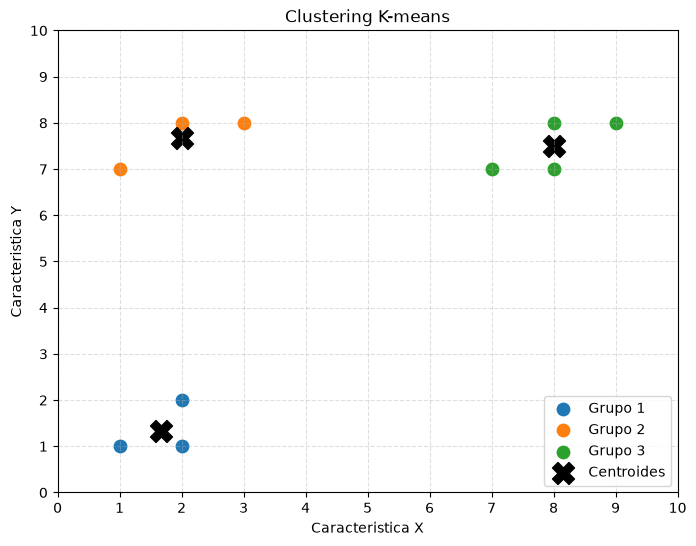

In [114]:
plt.figure(figsize=(8, 6))

for group in range(k):
    group_points = datos[np.array(groups) == group]

    plt.scatter(
        group_points[:, 0],
        group_points[:, 1],
        label=f"Grupo {group + 1}",
        s=80
    )

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroides"
)

plt.title("Clustering K-means")
plt.xlabel("Caracteristica X")
plt.ylabel("Caracteristica Y")

plt.xticks(range(0, 11))
plt.yticks(range(0, 11))
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.show()

<h1>Implementacion de k optimo</h1>

In [103]:
#deifnicion de los parametros de k means como el numero de iteraciones y la seed
#para obetener los mismo resultados con diferentes valores de k
def kmeans(datos, k, max_interactions=100, seed=42):
    rng = np.random.default_rng(seed)
    centroids = datos[rng.choice(len(datos), k, replace=False)]

    for iteration in range(max_interactions):
        groups = []

        # Asignacion de cada punto al centroide mas cercano
        for point in datos:
            distances = []
            
            for centroid in centroids:
                distance = np.sqrt(np.sum((point - centroid) ** 2))
                distances.append(distance)
                
            near_group = distances.index(min(distances))
            groups.append(near_group)

        #actualizacion de cada centroide para pasar al promedio de sus puntos
        new_centroids = []
        
        for group in range(k):
            group_points = []
            
            for i in range(len(datos)):
                if groups[i] == group:
                    group_points.append(datos[i])

            if len(group_points) > 0:
                new_centroid = np.mean(group_points, axis=0)
            else:
                new_centroid = centroids[group]#caso para si algun punto no pertenezca a el cluster se quede ahi mismo

            new_centroids.append(new_centroid)

        new_centroids = np.array(new_centroids)

        #comprobacion para obsiervar si los centroides ya no cambian, entonces terminamos
        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    # la suma de las distancis al cuadrado por cada punto a su centroide para sacar la inercia
    inertia = 0
    for i in range(len(datos)):
        centroid = centroids[groups[i]]
        inertia += np.sum((datos[i] - centroid) ** 2)

    return centroids, np.array(groups), inertia

<h2>Elbow</h2>

In [104]:
k_range = range(2, 11) #rango de grupos que se van a probar
inertias = []

for k in k_range:
    centroids, groups, inertia = kmeans(datos, k) #usa el valor k y guarda datos
    inertias.append(inertia) # guardamos la inercia
    print(f"k={k} | inercia={inertia:.2f}")

k=2 | inercia=69.92
k=3 | inercia=7.00
k=4 | inercia=4.83
k=5 | inercia=4.33
k=6 | inercia=2.33
k=7 | inercia=2.33
k=8 | inercia=1.00
k=9 | inercia=0.50
k=10 | inercia=0.00


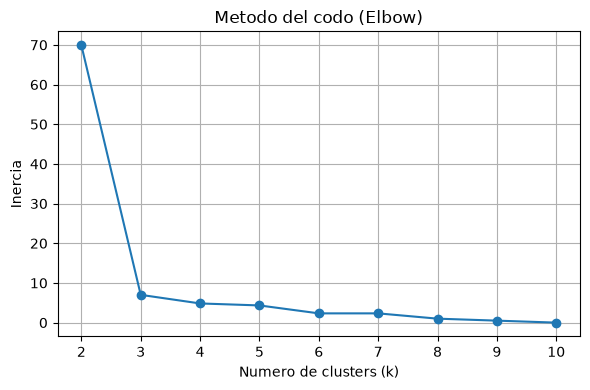

In [105]:
plt.figure(figsize=(6, 4))
plt.plot(list(k_range), inertias, "o-")
plt.title("Metodo del codo (Elbow)")
plt.xlabel("Numero de clusters (k)")
plt.ylabel("Inercia")
plt.grid(True)
plt.tight_layout()
plt.show()

<h2>Silhouette analysis</h2>

In [116]:
def silhouette_score(datos, groups):
    n = len(datos)
    clusters = np.unique(groups)

    if len(clusters) < 2: #Comprobacion para menos de 2 grupos
        return 0.0

    silhouettes = []

    for i in range(n): #recorremos todos los puntos
        own_cluster = groups[i] #obtencion del grupo del punto

        # a(i): distancia media dentro de su cluster
        same = [j for j in range(n) if groups[j] == own_cluster and j != i]
        #indices de los puntos del grupo
        if len(same) == 0: #comprobacion para ver si el punto esta solo
            silhouettes.append(0.0)  # si el punto estasolo agraega un coeficiente de 0
            continue

        a = np.mean([np.sqrt(np.sum((datos[i] - datos[j]) ** 2)) for j in same])
        #calculo de la distancia media entre el pinto actual y los demas del grupo

        # b(i): menor distancia media hacia otro cluster
        b = np.inf #menor distancia desde el punto a otro grupo
        for other in clusters: 
            if other == own_cluster: #para omitir el mismo grupo
                continue
            others = [j for j in range(n) if groups[j] == other] #lista con indices de otro grupo
            mean_dist = np.mean(
                [np.sqrt(np.sum((datos[i] - datos[j]) ** 2)) for j in others]
            )
            #calculo distancia euclidiana
            
            if mean_dist < b: #comprobacion si la distancia medie es menor que el actual y conservacion de la menor
                b = mean_dist

        s = (b - a) / max(a, b) #calculo de la silueta
        silhouettes.append(s)

    return np.mean(silhouettes) #calculo del promedio de siluetas


k_range = range(2, 11) #rango de grupos que se van a probar
silhouettes = []

for k in k_range:
    centroids, groups, inertia = kmeans(datos, k) #usa el valor k y guarda datos
    sil = silhouette_score(datos, groups) # usamos la funcion y obtenemos el promedio general
    silhouettes.append(sil)
    print(f"k={k} | silhouette={sil:.4f}")

best_k = list(k_range)[int(np.argmax(silhouettes))]
print(f"\nMejor k segun Silhouette: {best_k}")

k=2 | silhouette=0.4812
k=3 | silhouette=0.7721
k=4 | silhouette=0.6258
k=5 | silhouette=0.5313
k=6 | silhouette=0.3536
k=7 | silhouette=0.2520
k=8 | silhouette=0.1139
k=9 | silhouette=0.0293
k=10 | silhouette=0.0000

Mejor k segun Silhouette: 3


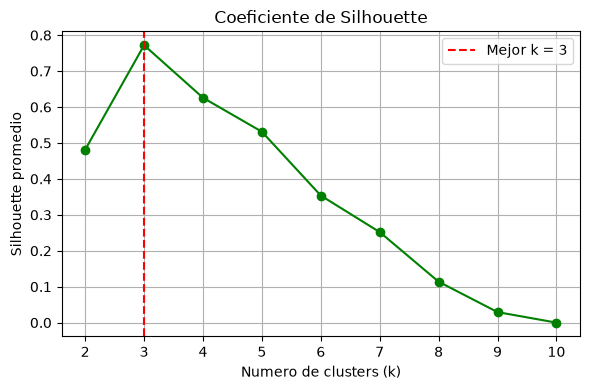

In [107]:
plt.figure(figsize=(6, 4))
plt.plot(list(k_range), silhouettes, "o-", color="green")
plt.axvline(best_k, color="red", linestyle="--", label=f"Mejor k = {best_k}")
plt.title("Coeficiente de Silhouette")
plt.xlabel("Numero de clusters (k)")
plt.ylabel("Silhouette promedio")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()